# Project Review 4 (Unit 4): Tracking a Surgical Robot End-Effector with HMM and Kalman Filtering (LDS)

**Problem statement:** Smooth and accurately track the 3D position and orientation of surgical robotic end-effectors under visual occlusions and sensor jitter, by combining stereoscopic vision data using Kalman filtering within an LDS framework.

**Dataset:** JIGSAWS (JHU-ISI Gesture and Skill Assessment Working Set), da Vinci robot, *Suturing* task. We use the kinematics of the patient-side manipulator PSM2 (columns 58-76, called the left PSM in the dataset paper): 3D position, rotation matrix, velocity and gripper angle and the gesture labels (G1, G2, ...).

## Pipeline

| Part | Step | Unit 4 topic |
|---|---|---|
| **A. Sequential model of surgical gestures** | 1. Load data, quantize motion into discrete symbols | |
| | 2. Gesture transition matrix | Markov models |
| | 3. HMM = (pi, A, B) | HMM |
| | 4. Forward-backward with scaling factors | Forward-backward, scaling factors |
| | 5. Same result via message passing on a chain | Sum-product algorithm |
| | 6. Train with Baum-Welch (EM) | Maximum likelihood for the HMM |
| | 7. Decode gesture sequence | Viterbi algorithm |
| | 8. Predict the next step | Practice 1 |
| **B. Tracking the end-effector** | 9. Virtual stereo cameras + jitter, then triangulate to 3D | Problem statement |
| | 10. Add occlusions (missing measurements) | Problem statement |
| | 11. State-space model of the tool motion | Linear dynamical system |
| | 12. Kalman filter (predict, update when visible) | Linear dynamical system |
| | 13. Compare against ground truth (RMSE) | |

## 0. Imports and settings

In [1]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(0)

# ---- settings (edit DATA_DIR only) ----
DATA_DIR = None         # leave as None: the notebook searches for the JIGSAWS Suturing folder itself
                        # (or set it by hand, e.g. "/kaggle/input/jigsaws-suturing")
DS       = 6            # HMM works at 30/6 = 5 Hz (take every 6th frame)
N_TEST   = 6            # last 6 trials are held out for testing the HMM
SMOOTH   = 0.5          # pseudo-count so that no probability is exactly zero

# column positions of PSM2 (columns 58-76 of the 76-column JIGSAWS kinematics file)
POS, ROT, VEL, GRIP = slice(57, 60), slice(60, 69), slice(69, 72), 75

## 1. Add the dataset, then load it

**You must attach the data before running this cell.** What to attach: the unzipped JIGSAWS **Suturing** folder, but only its two sub-folders
`kinematics` and `transcriptions` (skip `video`, it is huge and not used).

- **Kaggle:** right sidebar, *Add Input*, *Upload*, *New Dataset*; drag in the `kinematics` and `transcriptions` folders, name it (e.g. `jigsaws-suturing`), *Create*. It appears under `/kaggle/input/`.
- **Colab / Jupyter:** upload the two folders (or a zip of them and unzip it) next to the notebook.

The next cell finds the folder automatically by looking for `kinematics/AllGestures`.

### Load

Each JIGSAWS kinematics row (30 Hz) has 76 numbers. For PSM2 (the last 19 columns, 58-76) we use:
position (x, y, z), a 3x3 rotation matrix (orientation), linear velocity, and the gripper angle.
The transcription file lists gesture segments as `start_frame end_frame gesture_id`.

In [4]:
from google.colab import files
up = files.upload()          # a "Choose Files" button appears: pick jigsaws.zip
!unzip -q jigsaws.zip -d Suturing
!ls Suturing                 # should show: kinematics  transcriptions

Saving jigsaws.zip to jigsaws.zip
kinematics  transcriptions


In [6]:
def find_data_dir():
    hits = []
    for root in [".", "/content", "/kaggle/input", "/kaggle/working"]:
        hits += glob.glob(os.path.join(root, "**", "kinematics", "AllGestures"), recursive=True)
    hits = [h for h in hits if "__MACOSX" not in h]
    hits.sort(key=lambda h: "suturing" not in h.lower())          # prefer a path that mentions Suturing
    return os.path.dirname(os.path.dirname(hits[0])) if hits else None

if DATA_DIR is None:
    DATA_DIR = find_data_dir()
if DATA_DIR is None or not os.path.isdir(f"{DATA_DIR}/transcriptions"):
    raise FileNotFoundError(
        "JIGSAWS data not found. Attach the Suturing 'kinematics' and 'transcriptions' folders "
        "(see the instructions above), or set DATA_DIR to the folder that contains them.")
print("using data folder:", DATA_DIR)

def load_trial(name):
    kin = np.loadtxt(f"{DATA_DIR}/kinematics/AllGestures/{name}.txt")
    gest = np.full(len(kin), "", dtype=object)
    for line in open(f"{DATA_DIR}/transcriptions/{name}.txt"):
        if line.strip():
            s, e, g = line.split()[:3]
            gest[int(s) - 1:int(e)] = g          # frames are 1-indexed, inclusive
    idx = np.where(gest != "")[0]                # keep only the labelled part
    a, b = idx[0], idx[-1] + 1
    return kin[a:b], gest[a:b]

names = sorted(os.path.basename(f)[:-4] for f in glob.glob(f"{DATA_DIR}/kinematics/AllGestures/*.txt")
               if not os.path.basename(f).startswith(".") and os.path.exists(f"{DATA_DIR}/transcriptions/{os.path.basename(f)}"))
trials = {n: load_trial(n) for n in names}
train_names, test_names = names[:-N_TEST], names[-N_TEST:]

vocab = sorted({g for _, gest in trials.values() for g in gest}, key=lambda s: int(s[1:]))
g2i = {g: i for i, g in enumerate(vocab)}
K = len(vocab)
print(f"{len(names)} trials | train: {len(train_names)}, test: {len(test_names)}")
print("gestures (hidden states):", vocab)

using data folder: ./Suturing
39 trials | train: 33, test: 6
gestures (hidden states): ['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G8', 'G9', 'G10', 'G11']


# Part A: Sequential model of surgical gestures

## 2. Markov model: gesture transitions

A (first-order) Markov chain assumes the next gesture depends only on the current one:

$$p(z_1,\dots,z_N)=p(z_1)\prod_{n=2}^{N}p(z_n\mid z_{n-1}),\qquad A_{jk}=p(z_n=k\mid z_{n-1}=j)$$

Here $z_n$ is the gesture at step $n$. We estimate $A$ by counting transitions in the training trials (this is maximum likelihood for a Markov chain).

The continuous motion is turned into a discrete **observation symbol** $x_n$ for the HMM: speed of the tool (4 levels, by quartile) x gripper angle (3 levels, by tercile) = 12 symbols.

steps per trial (5 Hz): [926, 570, 545, 543, 475] ...


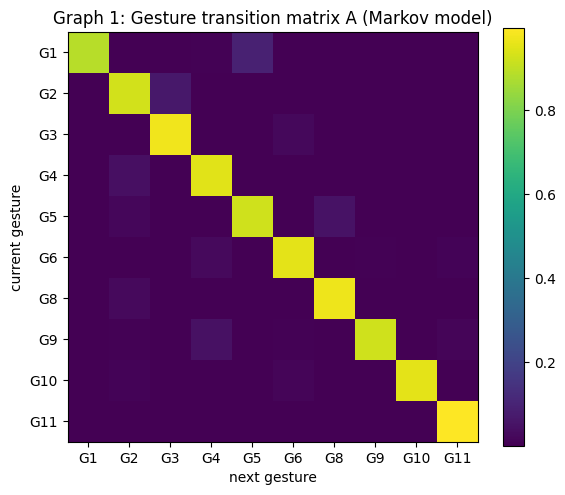

In [7]:
def get_features(kin):
    k = kin[::DS]
    return np.linalg.norm(k[:, VEL], axis=1), k[:, GRIP]

# bin edges come from the training trials only
tr_speed = np.concatenate([get_features(trials[n][0])[0] for n in train_names])
tr_grip  = np.concatenate([get_features(trials[n][0])[1] for n in train_names])
speed_edges = np.quantile(tr_speed, [.25, .50, .75])
grip_edges  = np.quantile(tr_grip,  [1/3, 2/3])
M = 4 * 3

def make_sequences(name):
    kin, gest = trials[name]
    speed, grip = get_features(kin)
    obs = np.digitize(speed, speed_edges) * 3 + np.digitize(grip, grip_edges)   # symbol 0..11
    states = np.array([g2i[g] for g in gest[::DS]])
    return states, obs

train = [make_sequences(n) for n in train_names]
test  = [make_sequences(n) for n in test_names]
print("steps per trial (5 Hz):", [len(s) for s, _ in train][:5], "...")

def ml_counts(seqs, smooth=SMOOTH):
    # Maximum likelihood when states ARE observed = normalised counts
    pi = np.full(K, smooth); A = np.full((K, K), smooth); B = np.full((K, M), smooth)
    for s, o in seqs:
        pi[s[0]] += 1
        np.add.at(A, (s[:-1], s[1:]), 1)
        np.add.at(B, (s, o), 1)
    return pi / pi.sum(), A / A.sum(1, keepdims=True), B / B.sum(1, keepdims=True)

pi0, A0, B0 = ml_counts(train)

# ---- Graph 1: Markov transition matrix ----
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(A0, cmap="viridis")
ax.set_xticks(range(K)); ax.set_xticklabels(vocab); ax.set_yticks(range(K)); ax.set_yticklabels(vocab)
ax.set_xlabel("next gesture"); ax.set_ylabel("current gesture")
ax.set_title("Graph 1: Gesture transition matrix A (Markov model)")
plt.colorbar(im); plt.tight_layout(); plt.show()

**Reading Graph 1:** the bright diagonal means a gesture usually continues for several steps. Bright off-diagonal cells show the typical order of gestures in suturing.

## 3. Hidden Markov Model

The gesture $z_n$ is *hidden* in real life; what we see is the motion symbol $x_n$. An HMM has three parts:

- initial distribution $\pi_k=p(z_1=k)$
- transition matrix $A_{jk}=p(z_n=k\mid z_{n-1}=j)$
- emission matrix $B_{km}=p(x_n=m\mid z_n=k)$

$$p(X,Z\mid\theta)=p(z_1)\prod_{n=2}^{N}p(z_n\mid z_{n-1})\prod_{n=1}^{N}p(x_n\mid z_n),\qquad \theta=\{\pi,A,B\}$$

`pi0, A0, B0` above are the maximum-likelihood estimates computed from the labelled gestures (smoothed with a small pseudo-count).

## 4. Forward-backward algorithm with scaling factors

Forward variable $\alpha(z_n)=p(x_1..x_n,z_n)$ becomes tiny for long sequences (underflow). The fix is to normalise at every step with the **scaling factor**

$$c_n=p(x_n\mid x_1..x_{n-1}),\qquad \hat\alpha(z_n)=\frac{\alpha(z_n)}{\prod_{m\le n}c_m}$$

$$c_n\hat\alpha(z_n)=p(x_n\mid z_n)\sum_{z_{n-1}}\hat\alpha(z_{n-1})\,p(z_n\mid z_{n-1})$$

Backward: $c_{n+1}\hat\beta(z_n)=\sum_{z_{n+1}}\hat\beta(z_{n+1})\,p(x_{n+1}\mid z_{n+1})\,p(z_{n+1}\mid z_n)$

Posterior state probability: $\gamma(z_n)=\hat\alpha(z_n)\hat\beta(z_n)$.  Log-likelihood: $\ln p(X)=\sum_n\ln c_n$.

In [8]:
def forward(pi, A, B, obs):
    N = len(obs); alpha = np.zeros((N, len(pi))); c = np.zeros(N)
    a = pi * B[:, obs[0]]
    c[0] = a.sum(); alpha[0] = a / c[0]
    for n in range(1, N):
        a = (alpha[n-1] @ A) * B[:, obs[n]]
        c[n] = a.sum(); alpha[n] = a / c[n]
    return alpha, c

def backward(A, B, obs, c):
    N = len(obs); beta = np.ones((N, A.shape[0]))
    for n in range(N - 2, -1, -1):
        beta[n] = A @ (B[:, obs[n+1]] * beta[n+1]) / c[n+1]
    return beta

s, o = test[0]
alpha, c = forward(pi0, A0, B0, o)
beta = backward(A0, B0, o, c)
gamma = alpha * beta
print("sequence length:", len(o))
print("log-likelihood  :", np.log(c).sum())
print("gamma rows sum to 1:", np.allclose(gamma.sum(1), 1))

sequence length: 547
log-likelihood  : -966.343090299204
gamma rows sum to 1: True


## 5. Sum-product algorithm

The HMM is a chain-shaped factor graph: variable nodes $z_1\dots z_N$ and factors
$h(z_1)=p(z_1)p(x_1|z_1)$ and $f_n(z_{n-1},z_n)=p(z_n|z_{n-1})p(x_n|z_n)$.

The sum-product algorithm sends messages along the chain:

$$\mu_{f_n\to z_n}(z_n)=\sum_{z_{n-1}}f_n(z_{n-1},z_n)\,\mu_{z_{n-1}\to f_n}(z_{n-1})\quad\text{(forward)}$$
$$\mu_{f_{n+1}\to z_n}(z_n)=\sum_{z_{n+1}}f_{n+1}(z_n,z_{n+1})\,\mu_{f_{n+2}\to z_{n+1}}(z_{n+1})\quad\text{(backward)}$$

The marginal is the product of the two incoming messages: $p(z_n|X)\propto\mu_{\text{fwd}}\,\mu_{\text{bwd}}$. The forward message is $\alpha$ and the backward message is $\beta$, so **sum-product on the chain is exactly the forward-backward algorithm**. Below, messages are normalised at every step (the same idea as the scaling factors), and the result is checked against $\gamma$.

In [9]:
def sum_product(pi, A, B, obs):
    N, Kk = len(obs), len(pi)
    F = lambda n: A * B[:, obs[n]][None, :]        # factor f_n(z_{n-1}, z_n) as a K x K table
    fwd = np.zeros((N, Kk)); bwd = np.ones((N, Kk))
    m = pi * B[:, obs[0]]; fwd[0] = m / m.sum()    # message from h(z1)
    for n in range(1, N):
        m = fwd[n-1] @ F(n);  fwd[n] = m / m.sum()          # forward message
    for n in range(N - 2, -1, -1):
        m = F(n+1) @ bwd[n+1]; bwd[n] = m / m.sum()          # backward message
    marg = fwd * bwd
    return marg / marg.sum(1, keepdims=True)

marg = sum_product(pi0, A0, B0, o)
print("Sum-product marginals equal forward-backward gamma:", np.allclose(marg, gamma))

Sum-product marginals equal forward-backward gamma: True


## 6. Maximum likelihood for the HMM: Baum-Welch (EM)

We want $\theta^{ML}=\arg\max_\theta\ln p(X\mid\theta)$. Summing over all hidden paths has no closed form, so EM alternates:

- **E-step:** with the current $\theta$, run forward-backward to get
  $\gamma(z_n)=p(z_n|X)$ and $\xi(z_{n-1},z_n)=p(z_{n-1},z_n|X)=\dfrac{\hat\alpha(z_{n-1})\,p(x_n|z_n)\,p(z_n|z_{n-1})\,\hat\beta(z_n)}{c_n}$
- **M-step:** re-estimate

$$\pi_k=\frac{\gamma(z_{1k})}{\sum_j\gamma(z_{1j})},\quad A_{jk}=\frac{\sum_n\xi(z_{n-1,j},z_{nk})}{\sum_l\sum_n\xi(z_{n-1,j},z_{nl})},\quad B_{km}=\frac{\sum_n\gamma(z_{nk})\,[x_n=m]}{\sum_n\gamma(z_{nk})}$$

Each iteration can only increase the likelihood. We start from the count-based estimates `pi0, A0, B0` so each state keeps the meaning of its gesture.

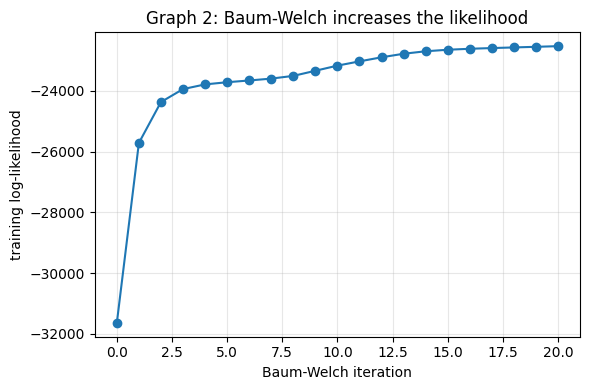

monotonic increase: True


In [10]:
def baum_welch(seqs, pi, A, B, n_iter=20):
    ll_hist = []
    for it in range(n_iter + 1):
        pi_n = np.zeros(K); A_n = np.zeros((K, K)); B_n = np.zeros((K, M)); ll = 0.0
        for _, obs in seqs:
            alpha, c = forward(pi, A, B, obs)
            beta = backward(A, B, obs, c)
            gam = alpha * beta
            ll += np.log(c).sum()
            pi_n += gam[0]
            W = (B[:, obs[1:]].T * beta[1:]) / c[1:, None]
            A_n += A * (alpha[:-1].T @ W)                   # sum over n of xi
            B_n += gam.T @ np.eye(M)[obs]
        ll_hist.append(ll)
        if it == n_iter: break
        pi = pi_n / pi_n.sum()
        A = A_n / A_n.sum(1, keepdims=True)
        B = B_n / B_n.sum(1, keepdims=True)
    return pi, A, B, ll_hist

pi1, A1, B1, ll_hist = baum_welch(train, pi0, A0, B0, n_iter=20)

# ---- Graph 2: log-likelihood vs EM iteration ----
plt.figure(figsize=(6, 4))
plt.plot(ll_hist, "o-")
plt.xlabel("Baum-Welch iteration"); plt.ylabel("training log-likelihood")
plt.title("Graph 2: Baum-Welch increases the likelihood"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("monotonic increase:", all(np.diff(ll_hist) > -1e-6))

## 7. Viterbi algorithm

Forward-backward gives the most probable state *at each step*. Viterbi (max-sum) gives the most probable **whole sequence** $\arg\max_{z_{1:N}}p(z_{1:N}|X)$:

$$\omega(z_n)=\ln p(x_n|z_n)+\max_{z_{n-1}}\big[\ln p(z_n|z_{n-1})+\omega(z_{n-1})\big]$$

We keep the arg-max at each step and backtrack from the end. Logs are used, which plays the same role as scaling.

Viterbi gesture accuracy on unseen trials | count-based ML: 0.228 | after Baum-Welch: 0.203
Note: Baum-Welch maximises the likelihood of the observed symbols, not gesture accuracy, so its states can drift from the gesture meaning.


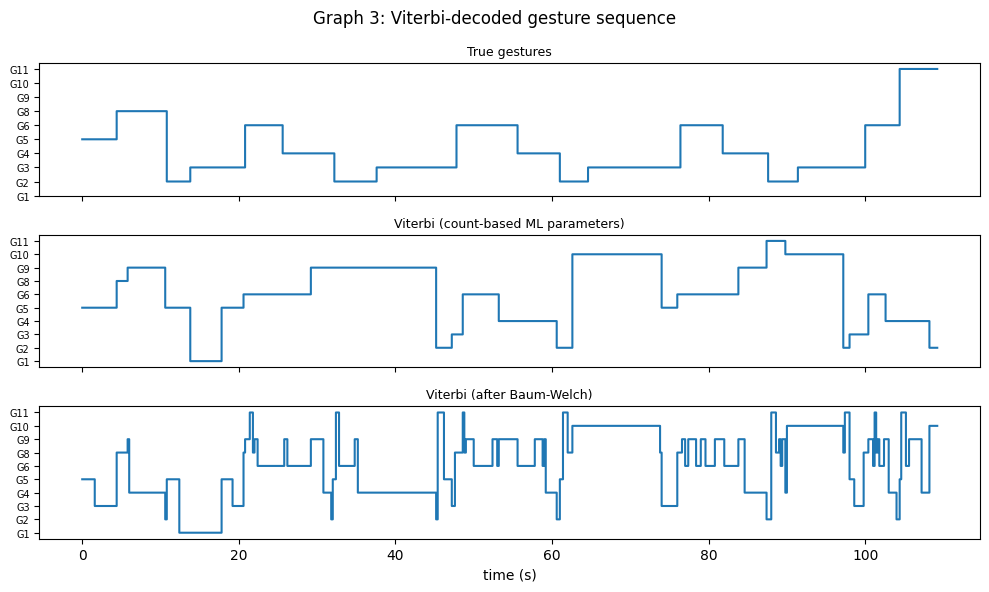

In [11]:
def viterbi(pi, A, B, obs):
    N = len(obs)
    with np.errstate(divide="ignore"):
        lpi, lA, lB = np.log(pi), np.log(A), np.log(B)
    w = np.zeros((N, K)); psi = np.zeros((N, K), dtype=int)
    w[0] = lpi + lB[:, obs[0]]
    for n in range(1, N):
        sc = w[n-1][:, None] + lA
        psi[n] = sc.argmax(0)
        w[n] = sc.max(0) + lB[:, obs[n]]
    path = np.zeros(N, dtype=int); path[-1] = w[-1].argmax()
    for n in range(N - 2, -1, -1):
        path[n] = psi[n+1, path[n+1]]
    return path

def accuracy(params, seqs):
    hit = tot = 0
    for s, o in seqs:
        hit += (viterbi(*params, o) == s).sum(); tot += len(s)
    return hit / tot

acc0 = accuracy((pi0, A0, B0), test); acc1 = accuracy((pi1, A1, B1), test)
print(f"Viterbi gesture accuracy on unseen trials | count-based ML: {acc0:.3f} | after Baum-Welch: {acc1:.3f}")
print("Note: Baum-Welch maximises the likelihood of the observed symbols, not gesture accuracy, so its states can drift from the gesture meaning.")

# ---- Graph 3: decoded vs true gestures for one test trial ----
s, o = test[0]
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for ax, y, ttl in zip(axs, [s, viterbi(pi0, A0, B0, o), viterbi(pi1, A1, B1, o)],
                      ["True gestures", "Viterbi (count-based ML parameters)", "Viterbi (after Baum-Welch)"]):
    ax.step(np.arange(len(y)) * DS / 30, y, where="post"); ax.set_yticks(range(K)); ax.set_yticklabels(vocab, fontsize=7)
    ax.set_title(ttl, fontsize=9)
axs[-1].set_xlabel("time (s)"); fig.suptitle("Graph 3: Viterbi-decoded gesture sequence"); plt.tight_layout(); plt.show()

## 8. Practice 1: HMM to predict the sequential data

Given the observations so far, the filtered state distribution is $\hat\alpha(z_n)$. One step ahead:

$$p(z_{n+1}\mid x_{1:n})=\hat\alpha(z_n)A,\qquad p(x_{n+1}\mid x_{1:n})=\Big[\hat\alpha(z_n)A\Big]B$$

We predict (a) the next gesture and (b) the next motion symbol on the **held-out trials**, and compare with simple baselines.

In [12]:
def predict_next(params, seqs):
    pi, A, B = params; g_hit = x_hit = rep_hit = tot = 0
    for s, o in seqs:
        alpha, _ = forward(pi, A, B, o)
        z_next = alpha[:-1] @ A                         # p(z_{n+1} | x_1..n)
        x_next = z_next @ B                             # p(x_{n+1} | x_1..n)
        g_hit   += (z_next.argmax(1) == s[1:]).sum()
        x_hit   += (x_next.argmax(1) == o[1:]).sum()
        rep_hit += (o[:-1] == o[1:]).sum()              # baseline: symbol stays the same
        tot += len(s) - 1
    return g_hit / tot, x_hit / tot, rep_hit / tot

major_g = np.bincount(np.concatenate([s for s, _ in train]), minlength=K).argmax()
major_acc = np.mean(np.concatenate([s[1:] for s, _ in test]) == major_g)

for label, prm in [("count-based ML", (pi0, A0, B0)), ("Baum-Welch   ", (pi1, A1, B1))]:
    g, x, rep = predict_next(prm, test)
    print(f"{label} | next-gesture acc: {g:.3f} | next-symbol acc: {x:.3f}")
print(f"baselines      | most-frequent gesture: {major_acc:.3f} | repeat last symbol: {rep:.3f}")

count-based ML | next-gesture acc: 0.257 | next-symbol acc: 0.308
Baum-Welch    | next-gesture acc: 0.193 | next-symbol acc: 0.463
baselines      | most-frequent gesture: 0.324 | repeat last symbol: 0.489


# Part B: Tracking the end-effector with a Linear Dynamical System

## 9. Ground truth and virtual stereo cameras

JIGSAWS gives the true tool pose from the robot, but no camera calibration. So we use the robot pose as **ground truth** and create the stereo measurements ourselves:

1. Two virtual cameras (left and right, baseline $b$, focal length $f$) project the 3D tool tip to pixels.
2. **Sensor jitter:** Gaussian noise is added to each pixel coordinate.
3. **Triangulation:** with disparity $d=u_L-u_R$ we recover $Z=\dfrac{fb}{d},\;X=\dfrac{(u_L-c_x)Z}{f},\;Y=\dfrac{(v-c_y)Z}{f}$.
4. **Orientation** (roll, pitch, yaw from the rotation matrix) is measured with small Gaussian noise, as the stereo orientation estimate.

Depth is noisier than X and Y because $\delta Z\propto Z^2/(fb)\,\delta d$. This is the main reason a filter is needed.

In [13]:
TRACK_TRIAL = test_names[0]
kin, gest = trials[TRACK_TRIAL]
dt = 1 / 30
pos_true = kin[:, POS]                                                   # (N,3) metres
eul_true = np.unwrap(R.from_matrix(kin[:, ROT].reshape(-1, 3, 3)).as_euler("xyz"), axis=0)   # (N,3) radians
truth = np.hstack([pos_true, eul_true])                                  # 6 degrees of freedom
N = len(truth)

# virtual stereo rig
f, b, cx, cy = 800.0, 0.005, 320.0, 240.0        # focal length (px), baseline (m), principal point (px)
sigma_pix, sigma_ang = 0.5, np.deg2rad(3)         # jitter: 0.5 px in every image coordinate, 3 degrees in orientation

shift = -pos_true.mean(0); shift[2] += np.abs(pos_true[:, 2] - pos_true[:, 2].mean()).max() + 0.10   # put tool in front of cameras
P = pos_true + shift
uL = f * P[:, 0] / P[:, 2] + cx;        vL = f * P[:, 1] / P[:, 2] + cy
uR = f * (P[:, 0] - b) / P[:, 2] + cx;  vR = vL.copy()
uL, vL, uR, vR = [a + rng.normal(0, sigma_pix, N) for a in (uL, vL, uR, vR)]    # sensor jitter

Z = f * b / (uL - uR)                                   # triangulation
X = (uL - cx) * Z / f
Y = ((vL + vR) / 2 - cy) * Z / f
pos_meas = np.c_[X, Y, Z] - shift
z_all = np.hstack([pos_meas, eul_true + rng.normal(0, sigma_ang, (N, 3))])      # noisy 6-D measurement

print(f"trial {TRACK_TRIAL}: {N} frames ({N*dt:.0f} s)")
print("position jitter std (mm) x,y,z:", 1000 * (pos_meas - pos_true).std(0))

trial Suturing_H005: 3279 frames (109 s)
position jitter std (mm) x,y,z: [0.52  0.222 3.529]


## 10. Visual occlusions

Occlusion means the camera loses the tool, so **no measurement** arrives. We hide 5 windows of 1 second (30 frames) at random places.

In [14]:
occluded = np.zeros(N, dtype=bool)
for seg in np.array_split(np.arange(N), 5):
    start = rng.integers(seg[0] + 30, seg[-1] - 60)
    occluded[start:start + 30] = True
z_obs = z_all.copy(); z_obs[occluded] = np.nan
print(f"occluded frames: {occluded.sum()} of {N} ({100*occluded.mean():.0f}%)")

occluded frames: 150 of 3279 (5%)


## 11. Linear dynamical system (LDS)

An LDS is the continuous-state analogue of an HMM: the hidden state $\mathbf z_n$ is a continuous vector, and both the transition and the emission are linear-Gaussian:

$$\mathbf z_n=\mathbf A\,\mathbf z_{n-1}+\mathbf w_n,\quad \mathbf w_n\sim\mathcal N(0,\mathbf Q)\qquad\text{(transition)}$$
$$\mathbf x_n=\mathbf C\,\mathbf z_n+\mathbf v_n,\quad \mathbf v_n\sim\mathcal N(0,\mathbf R)\qquad\text{(measurement)}$$

Our state holds the 6 pose values and their 6 rates of change, $\mathbf z=[x,y,z,\text{roll},\text{pitch},\text{yaw},\dot x,\dots,\dot{\text{yaw}}]$ (12 numbers), with a constant-velocity model:

$$\mathbf A=\begin{bmatrix}I&\Delta t\,I\\0&I\end{bmatrix},\qquad \mathbf C=\begin{bmatrix}I&0\end{bmatrix}$$

- $\mathbf R$: measurement (stereo jitter) covariance, estimated from the stereo error on visible frames.
- $\mathbf Q$: how much the tool's velocity can change in one step, set from the tool's typical acceleration (white-noise-acceleration model).

In [15]:
D = 6
A_lds = np.block([[np.eye(D), dt * np.eye(D)], [np.zeros((D, D)), np.eye(D)]])
C_lds = np.hstack([np.eye(D), np.zeros((D, D))])

# R: measurement noise covariance (from the stereo error on visible frames)
R_lds = np.diag(((z_all - truth)[~occluded]).var(0))

# Q: white-noise-acceleration model, one 2x2 block per degree of freedom
acc_var = np.var(np.diff(truth, 2, axis=0) / dt**2, axis=0)
q = acc_var * dt
Q_lds = np.zeros((2 * D, 2 * D))
for d in range(D):
    Q_lds[d, d] = q[d] * dt**3 / 3
    Q_lds[d, D + d] = Q_lds[D + d, d] = q[d] * dt**2 / 2
    Q_lds[D + d, D + d] = q[d] * dt

## 12. Kalman filter

At every frame:

**Predict** (always, even when the tool is hidden): $\;\hat{\mathbf z}_{n|n-1}=\mathbf A\hat{\mathbf z}_{n-1},\quad \mathbf P_{n|n-1}=\mathbf A\mathbf P_{n-1}\mathbf A^T+\mathbf Q$

**Update** (only if the stereo measurement is visible):
$$\mathbf K_n=\mathbf P_{n|n-1}\mathbf C^T(\mathbf C\mathbf P_{n|n-1}\mathbf C^T+\mathbf R)^{-1}$$
$$\hat{\mathbf z}_n=\hat{\mathbf z}_{n|n-1}+\mathbf K_n(\mathbf x_n-\mathbf C\hat{\mathbf z}_{n|n-1}),\qquad \mathbf P_n=(I-\mathbf K_n\mathbf C)\mathbf P_{n|n-1}$$

When the tool is occluded there is no update, so the filter "coasts" along the predicted motion and its uncertainty $\mathbf P$ grows. When the tool reappears, the update pulls the estimate back.

In [16]:
def kalman_filter(z, A, C, Q, Rm):
    N, D2 = len(z), A.shape[0]
    x = np.r_[z[0], np.zeros(D2 // 2)]                  # start at first measurement, zero velocity
    P = np.eye(D2) * 1e-2
    est = np.zeros((N, D2)); unc = np.zeros(N)
    for n in range(N):
        x = A @ x;  P = A @ P @ A.T + Q                 # predict
        if not np.isnan(z[n, 0]):                       # update only when measurement exists
            S = C @ P @ C.T + Rm
            Kg = P @ C.T @ np.linalg.inv(S)
            x = x + Kg @ (z[n] - C @ x)
            P = (np.eye(D2) - Kg @ C) @ P
        est[n] = x; unc[n] = np.trace(P[:3, :3])
    return est, unc

est, unc = kalman_filter(z_obs, A_lds, C_lds, Q_lds, R_lds)
kf = est[:, :D]

# baseline for occlusion: hold the last visible measurement
hold = z_obs.copy()
for n in range(1, N):
    if np.isnan(hold[n, 0]): hold[n] = hold[n-1]

## 13. Results

                                  position RMSE (mm)   orientation RMSE (deg)
Raw stereo (visible frames)                     3.59                     5.19
Kalman filter (visible frames)                  1.78                     3.28
Hold last value (occluded)                      8.99                    18.23
Kalman filter (occluded)                       11.29                    32.26


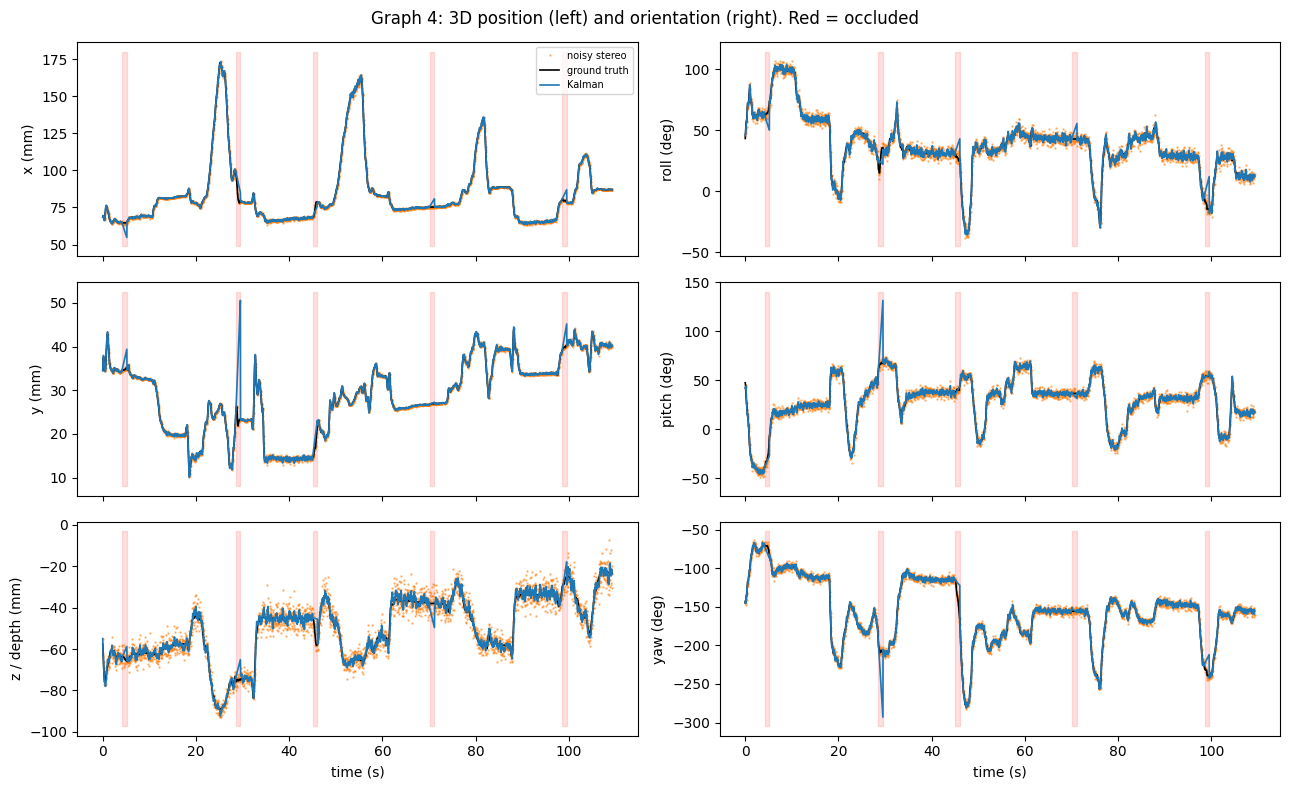

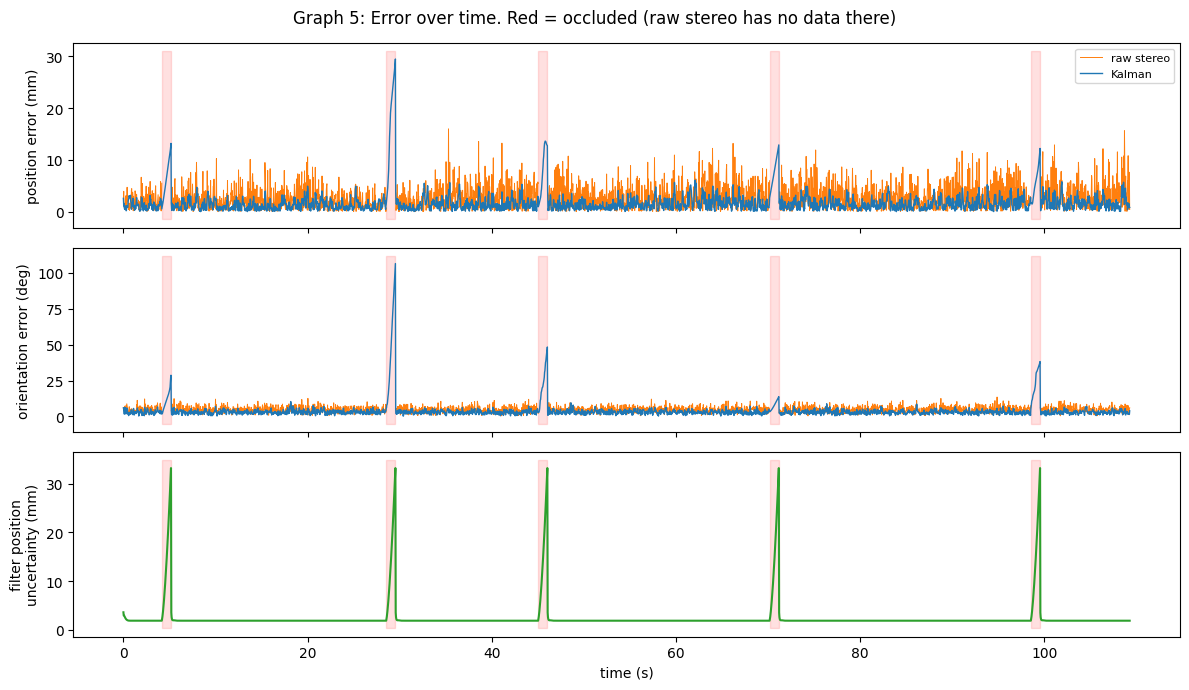

In [17]:
t = np.arange(N) * dt
def rmse_pos(a, m): return 1000 * np.sqrt(np.mean(np.sum((a[m, :3] - truth[m, :3])**2, 1)))     # mm
def rmse_ang(a, m): return np.rad2deg(np.sqrt(np.mean(np.sum((a[m, 3:] - truth[m, 3:])**2, 1))))  # degrees

vis = ~occluded
print(f"{'':32s}{'position RMSE (mm)':>20s}{'orientation RMSE (deg)':>25s}")
print(f"{'Raw stereo (visible frames)':32s}{rmse_pos(z_all, vis):20.2f}{rmse_ang(z_all, vis):25.2f}")
print(f"{'Kalman filter (visible frames)':32s}{rmse_pos(kf, vis):20.2f}{rmse_ang(kf, vis):25.2f}")
print(f"{'Hold last value (occluded)':32s}{rmse_pos(hold, occluded):20.2f}{rmse_ang(hold, occluded):25.2f}")
print(f"{'Kalman filter (occluded)':32s}{rmse_pos(kf, occluded):20.2f}{rmse_ang(kf, occluded):25.2f}")

# ---- Graph 4: trajectory, true vs measured vs Kalman ----
lab = ["x (mm)", "y (mm)", "z / depth (mm)", "roll (deg)", "pitch (deg)", "yaw (deg)"]
fig, axs = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
for d in range(6):
    ax = axs[d % 3, d // 3]; sc = 1000 if d < 3 else np.rad2deg(1)
    ax.plot(t, sc * z_all[:, d], ".", ms=1.5, color="tab:orange", alpha=.5, label="noisy stereo")
    ax.plot(t, sc * truth[:, d], color="k", lw=1.2, label="ground truth")
    ax.plot(t, sc * kf[:, d], color="tab:blue", lw=1.2, label="Kalman")
    ax.fill_between(t, *ax.get_ylim(), where=occluded, color="red", alpha=.12)
    ax.set_ylabel(lab[d])
axs[0, 0].legend(loc="upper right", fontsize=7); axs[2, 0].set_xlabel("time (s)"); axs[2, 1].set_xlabel("time (s)")
fig.suptitle("Graph 4: 3D position (left) and orientation (right). Red = occluded"); plt.tight_layout(); plt.show()

# ---- Graph 5: error over time ----
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axs[0].plot(t, 1000 * np.linalg.norm(z_obs[:, :3] - truth[:, :3], axis=1), color="tab:orange", lw=.7, label="raw stereo")
axs[0].plot(t, 1000 * np.linalg.norm(kf[:, :3] - truth[:, :3], axis=1), color="tab:blue", lw=1, label="Kalman")
axs[0].set_ylabel("position error (mm)"); axs[0].legend(fontsize=8)
axs[1].plot(t, np.rad2deg(np.linalg.norm(z_obs[:, 3:] - truth[:, 3:], axis=1)), color="tab:orange", lw=.7)
axs[1].plot(t, np.rad2deg(np.linalg.norm(kf[:, 3:] - truth[:, 3:], axis=1)), color="tab:blue", lw=1)
axs[1].set_ylabel("orientation error (deg)")
axs[2].plot(t, 1000 * np.sqrt(unc), color="tab:green"); axs[2].set_ylabel("filter position\nuncertainty (mm)")
for ax in axs: ax.fill_between(t, *ax.get_ylim(), where=occluded, color="red", alpha=.12)
axs[2].set_xlabel("time (s)"); fig.suptitle("Graph 5: Error over time. Red = occluded (raw stereo has no data there)")
plt.tight_layout(); plt.show()

## Conclusion

- **Part A:** Gestures form a Markov chain; the HMM links hidden gestures to observed motion symbols. Forward-backward with scaling factors (equivalently, sum-product on a chain) computes the likelihood and posteriors, Baum-Welch fits the parameters by maximum likelihood, Viterbi decodes the most probable gesture sequence, and the trained HMM predicts the next step.
- **Part B:** The tool's pose is modelled as a linear dynamical system. The Kalman filter combines the prediction with the noisy stereo measurement: it reduces jitter when the tool is visible and keeps tracking by prediction alone during occlusions, with growing uncertainty (Graph 5, bottom).
- **Limitations:** the stereo cameras are virtual (JIGSAWS has no calibration), the noise is Gaussian, and the constant-velocity model drifts during long occlusions.

*Data: JIGSAWS, Gao et al., "JHU-ISI Gesture and Skill Assessment Working Set (JIGSAWS): A Surgical Activity Dataset for Human Motion Modeling", M2CAI 2014.*